# Industrial solvers by backend

Set the reward criterion and model size below. Each backend has its own benchmark cell and performance profile, using the same 10 randomly selected catalogue MDPs. Linear programming methods from SciPy, Pyomo and QuantEcon share the backend `linear`.

Inspect each backend's methods and choose your preferred solver in the last section. That section benchmarks only your choices on the same MDPs. Each run saves its CSV and experiment manifest. The final comparison uses the selection sample; it is not an independent evaluation.

In [1]:
import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

from IPython.display import display

from mdpforge import Benchmark
from mdpforge.solvers import average, discounted, total

CRITERION = "discounted"  # "discounted", "total" or "average"
SIZE = "tiny"  # "tiny", "small", "medium" or "large"
N_MDPS = 10
DISCOUNT = 0.99
PRECISION = 1e-3
REPEATS = 5
SEED = 0
TIMEOUTS = {"tiny": 10, "small": 30, "medium": 60, "large": 360}
VALIDATE = False
MDPAX_MAX_EVENT_ENTRIES = 5_000_000

BACKENDS = [
    "marmote",
    "mdpsolver",
    "mdptoolbox",
    "madupite",
    "mdpax",
    "quantecon",
    "linear",
]
SOLVER_CATALOGUES = {
    "discounted": discounted,
    "total": total,
    "average": average,
}
results = {}

## Catalogue support

Unsupported backends and missing optional solver dependencies are skipped. Missing model dependencies can reduce the sample; the model cell stops if fewer than 10 MDPs load.

Profiles use median runtimes only when all repeats finish successfully. Failures remain in the denominator. Execution success does not certify solution quality. Set `VALIDATE = True` to request certification outside timing for discounted and total reward; this notebook keeps average validation disabled.

In [2]:
catalogue = SOLVER_CATALOGUES[CRITERION]
solver_entries = {entry["name"]: entry for entry in catalogue.list_solvers()}
backend_solvers = {
    backend: [
        name for name, entry in solver_entries.items() if entry["backend"] == backend
    ]
    for backend in BACKENDS
}
for backend, names in backend_solvers.items():
    print(f"{backend}: {', '.join(names) if names else 'not supported'}")

marmote: marmote_mpi, marmote_mpigs, marmote_vi, marmote_vigs
mdpsolver: mdpsolver_mpi, mdpsolver_mpigs, mdpsolver_mpigs_init, mdpsolver_mpisor, mdpsolver_mpisor_init, mdpsolver_pi, mdpsolver_vi, mdpsolver_vigs, mdpsolver_visor
mdptoolbox: mdptoolbox_mpi, mdptoolbox_pi, mdptoolbox_vi, mdptoolbox_vigs
madupite: madupite_ipi, madupite_ipi_bicgstab, madupite_ipi_gmres, madupite_ipi_tfqmr, madupite_opi, madupite_pi, madupite_vi
mdpax: mdpax_pi, mdpax_vi
quantecon: quantecon_mpi, quantecon_pi, quantecon_vi
linear: pyomo_dual, pyomo_primal, quantecon_lp, scipy_dual, scipy_primal


## Shared random sample

Run this cell once before the backend cells. Changing `CRITERION`, `SIZE` or `SEED` requires rerunning the setup cells. The seed controls catalogue sampling; model generation keeps its existing behavior.

In [3]:
bench = Benchmark(criterion=CRITERION)
bench.select_mdps_random(N_MDPS, size=SIZE, seed=SEED, verbose=True)
if len(bench._mdps) != N_MDPS:
    raise ValueError(
        f"Loaded {len(bench._mdps)} of {N_MDPS} sampled MDPs; "
        "install the missing model dependencies or choose another SEED."
    )
results.clear()
for model in bench._mdps:
    print(f"{model.name}: {model.state_dim} states, {model.action_dim} actions")

Loading/building model 'option_pricing'...
Added MDP '3601_2_optionpricing_60_60' (3601 states, 2 actions) in 0.004 s
Loading/building model 'windgrid'...
Added MDP '1224_4_windgrid' (1224 states, 4 actions) in 0.003 s
Loading/building model 'prism_rabin'...
Added MDP '27766_3_prismrabin_2_3_0_1' (27766 states, 3 actions) in 0.011 s
Loading/building model 'barto'...
Added MDP '726_9_barto_3_0.1' (726 states, 9 actions) in 0.005 s
Loading/building model 'jani_dining_philosophers'...
Added MDP 'jani_dining_philosophers' (956 states, 6 actions) in 0.049 s
Loading/building model 'qvbs_firewire'...
Added MDP 'qvbs_firewire' (1743 states, 3 actions) in 0.089 s
Loading/building model 'qvbs_echoring'...
Added MDP 'qvbs_echoring' (109515 states, 5 actions) in 6.092 s
Loading/building model 'peg_solitaire'...
Added MDP '500_36_pegsolitaire' (500 states, 36 actions) in 0.010 s
Loading/building model 'zenotravel'...
Added MDP '1206_6_zenotravel_1_86_6_0.12_0.015' (1206 states, 6 actions) in 0.005 

In [4]:
def solver_options(backend):
    """Return the configured constructor options for one backend."""
    if backend == "mdpax":
        return {"max_event_entries": MDPAX_MAX_EVENT_ENTRIES}
    return {}


def run_registered(label):
    """Benchmark the current solvers on the shared sample and show their profiles."""
    result = bench.run(
        discount=DISCOUNT if CRITERION == "discounted" else None,
        precision=PRECISION,
        repeats=REPEATS,
        seed=SEED,
        timeout=TIMEOUTS[SIZE],
        validate=VALIDATE and CRITERION != "average",
        verbose=True,
    )
    results[CRITERION, SIZE, label] = result
    csv_path = result.export_csv()
    print(f"{CRITERION} / {SIZE} / {label}: {csv_path}")
    display(
        result.solver_summary()[
            [
                "solver",
                "models_solved",
                "n_models",
                "fastest_rate",
                "within_2x",
                "median_ratio",
            ]
        ]
    )
    if VALIDATE and CRITERION != "average":
        display(
            result.to_dataframe()
            .groupby(["solver", "validation_status"])
            .size()
            .unstack(fill_value=0)
        )
    result.plot_performance_profile()
    result.plot_heat(metric="runtime")
    return result


def run_backend(backend):
    """Benchmark all installed methods from one backend."""
    bench.reset(models=False)
    if not backend_solvers[backend]:
        print(f"{backend} is not supported for {CRITERION} reward.")
        return None
    bench.add_solver(backend=backend, **solver_options(backend))
    if not bench._solvers:
        print(f"No installed solvers are available for {backend}.")
        return None
    return run_registered(backend)

## Marmote

3601_2_optionpricing_60_60 / marmote_mpi [1/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpi [2/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpi [3/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpi [4/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpi [5/5]: success (0.019 s)
3601_2_optionpricing_60_60 / marmote_mpigs [1/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpigs [2/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpigs [3/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpigs [4/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_mpigs [5/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_vi [1/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_vi [2/5]: success (0.015 s)
3601_2_optionpricing_60_60 / marmote_vi [3/5]: success (0.016 s)
3601_2_optionpricing_60_60 / marmote_vi [4/5]: success (0.016 s)
3601_2_optionpricing_60_60 / marmote_vi [5/5]: success (0.015 s)
3601_

,solver,models_solved,n_models,fastest_rate,within_2x,median_ratio
0,marmote_mpi,10,10,0.0,1.0,1.669021
1,marmote_mpigs,10,10,0.3,0.8,1.696904
2,marmote_vi,10,10,0.4,0.9,1.018218
3,marmote_vigs,10,10,0.3,0.9,1.006472


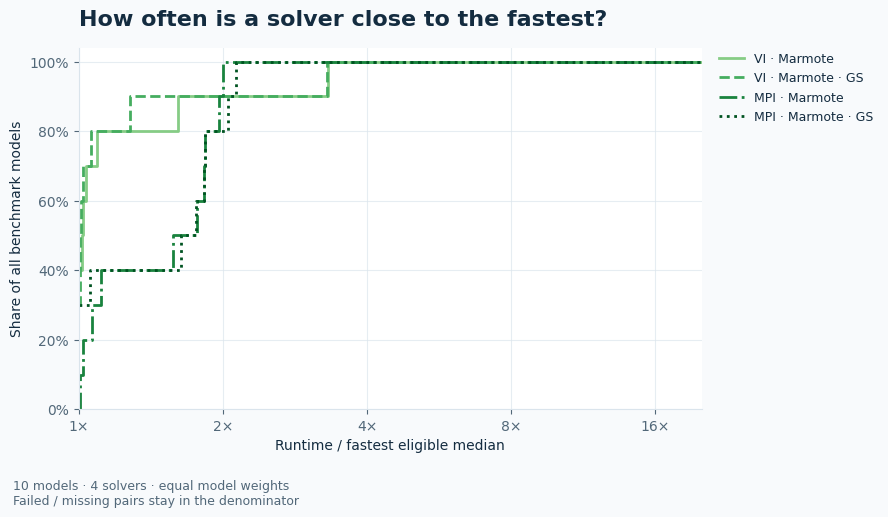

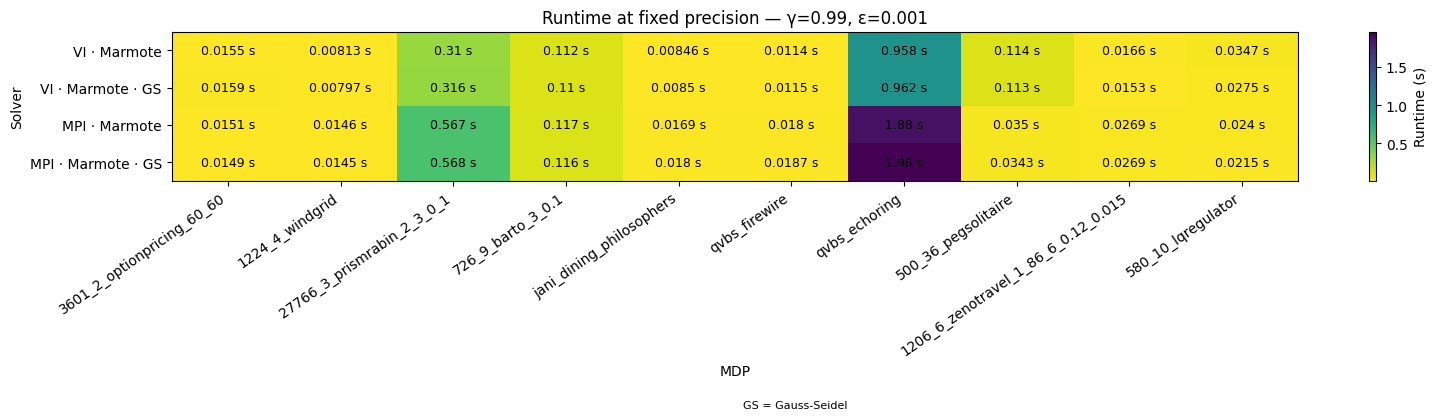

In [5]:
result_marmote = run_backend("marmote")

## MDPSolver

3601_2_optionpricing_60_60 / mdpsolver_mpi [1/5]: success (0.011 s)
3601_2_optionpricing_60_60 / mdpsolver_mpi [2/5]: success (0.012 s)
3601_2_optionpricing_60_60 / mdpsolver_mpi [3/5]: success (0.011 s)
3601_2_optionpricing_60_60 / mdpsolver_mpi [4/5]: success (0.011 s)
3601_2_optionpricing_60_60 / mdpsolver_mpi [5/5]: success (0.011 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs [1/5]: success (0.012 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs [2/5]: success (0.013 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs [3/5]: success (0.012 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs [4/5]: success (0.013 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs [5/5]: success (0.012 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs_init [1/5]: success (0.013 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs_init [2/5]: success (0.013 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs_init [3/5]: success (0.013 s)
3601_2_optionpricing_60_60 / mdpsolver_mpigs_init [4/5]: success (0.013 s)
3601_2_opt

,solver,models_solved,n_models,fastest_rate,within_2x,median_ratio
0,mdpsolver_mpi,10,10,0.3,0.9,1.020725
1,mdpsolver_mpigs,10,10,0.1,0.9,1.062284
2,mdpsolver_mpigs_init,10,10,0.1,1.0,1.074297
3,mdpsolver_mpisor,10,10,0.0,0.9,1.041416
4,mdpsolver_mpisor_init,10,10,0.0,1.0,1.076353
5,mdpsolver_pi,10,10,0.1,0.7,1.639809
6,mdpsolver_vi,10,10,0.3,0.9,1.019487
7,mdpsolver_vigs,9,10,0.1,0.3,7.956158
8,mdpsolver_visor,9,10,0.0,0.8,1.059299


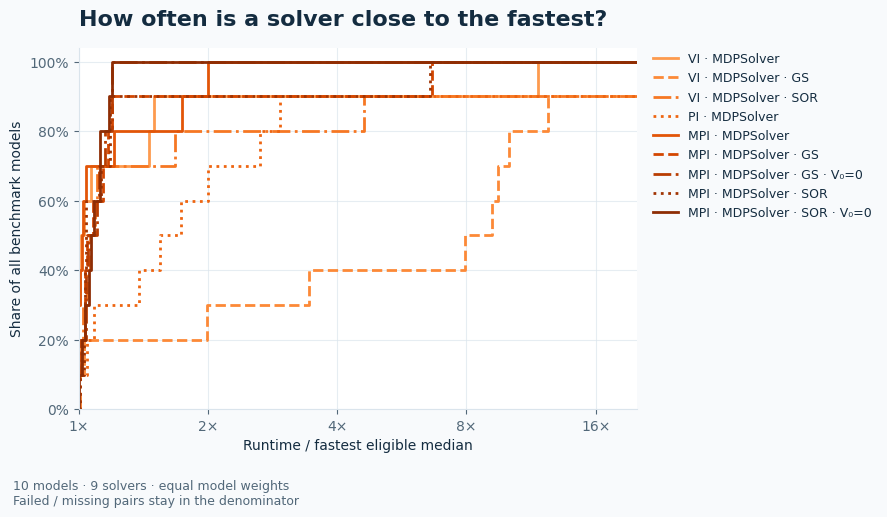

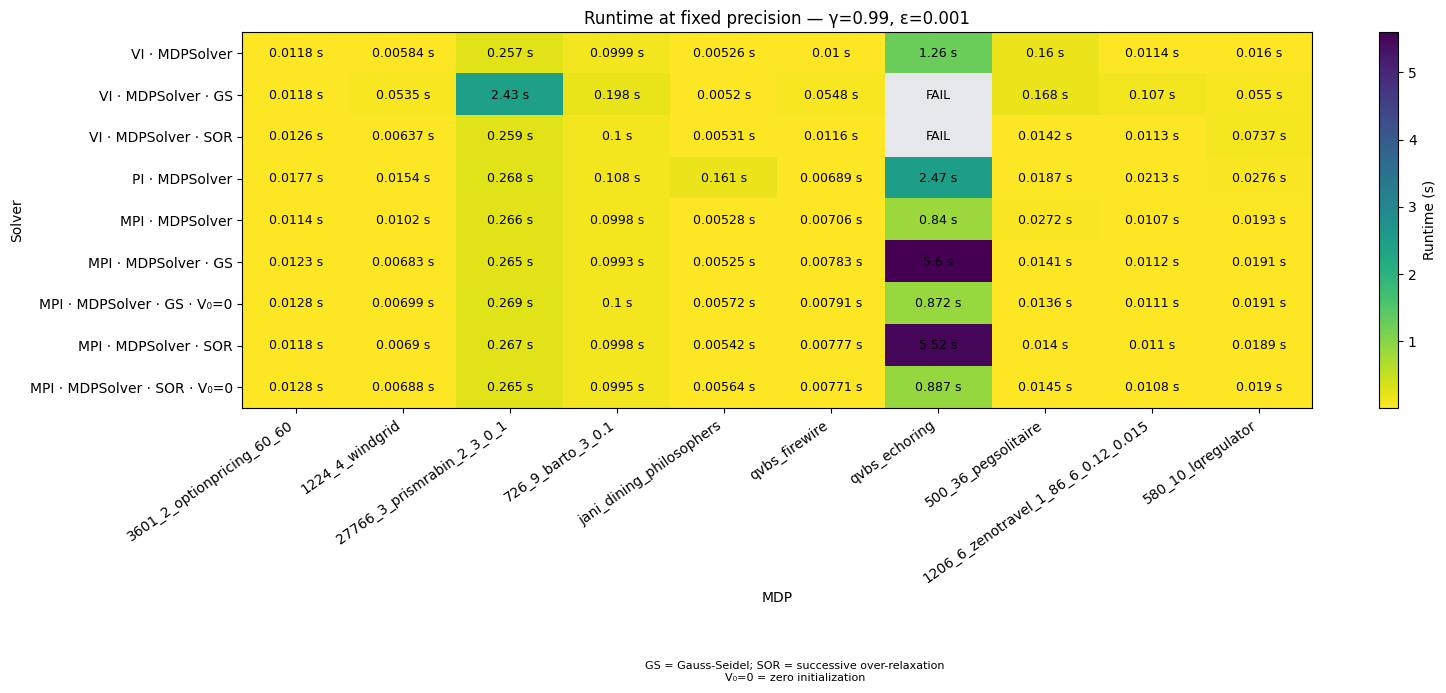

In [6]:
result_mdpsolver = run_backend("mdpsolver")

## MDPToolbox

3601_2_optionpricing_60_60 / mdptoolbox_mpi [1/5]: success (1.097 s)
3601_2_optionpricing_60_60 / mdptoolbox_mpi [2/5]: success (1.017 s)
3601_2_optionpricing_60_60 / mdptoolbox_mpi [3/5]: success (1.048 s)
3601_2_optionpricing_60_60 / mdptoolbox_mpi [4/5]: success (1.036 s)
3601_2_optionpricing_60_60 / mdptoolbox_mpi [5/5]: success (1.024 s)
3601_2_optionpricing_60_60 / mdptoolbox_pi [1/5]: success (1.925 s)
3601_2_optionpricing_60_60 / mdptoolbox_pi [2/5]: success (1.924 s)
3601_2_optionpricing_60_60 / mdptoolbox_pi [3/5]: success (1.916 s)
3601_2_optionpricing_60_60 / mdptoolbox_pi [4/5]: success (1.939 s)
3601_2_optionpricing_60_60 / mdptoolbox_pi [5/5]: success (1.911 s)
3601_2_optionpricing_60_60 / mdptoolbox_vi [1/5]: success (0.900 s)
3601_2_optionpricing_60_60 / mdptoolbox_vi [2/5]: success (0.913 s)
3601_2_optionpricing_60_60 / mdptoolbox_vi [3/5]: success (0.930 s)
3601_2_optionpricing_60_60 / mdptoolbox_vi [4/5]: success (0.908 s)
3601_2_optionpricing_60_60 / mdptoolbox_vi 

,solver,models_solved,n_models,fastest_rate,within_2x,median_ratio
0,mdptoolbox_mpi,8,10,0.3,0.7,1.167651
1,mdptoolbox_pi,7,10,0.3,0.5,1.226119
2,mdptoolbox_vi,7,10,0.2,0.4,1.799946
3,mdptoolbox_vigs,3,10,0.0,0.0,19.271371


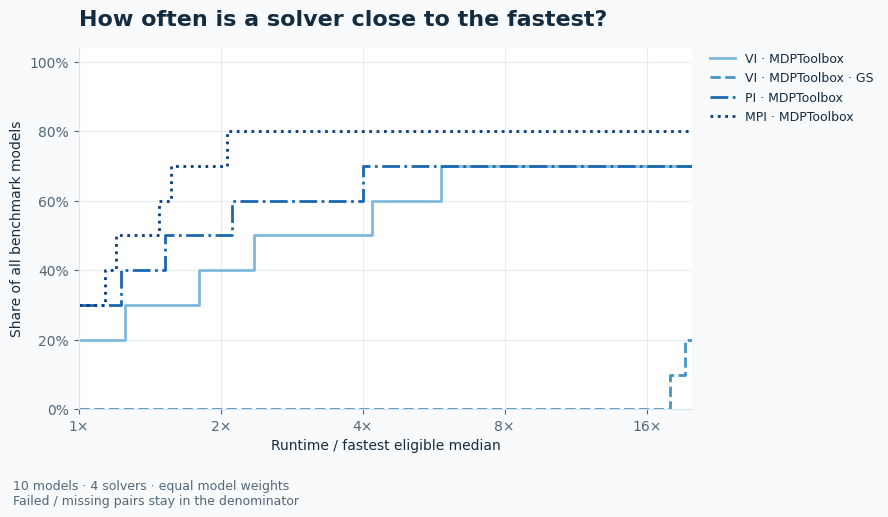

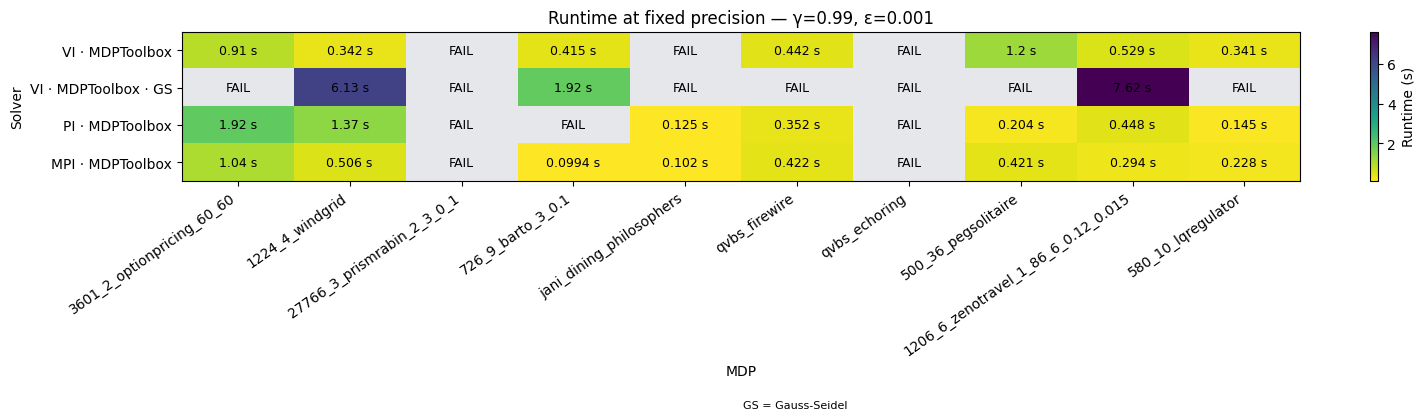

In [7]:
result_mdptoolbox = run_backend("mdptoolbox")

## madupite

In [8]:
result_madupite = run_backend("madupite")

No installed solvers are available for madupite.


C:\Users\orsof\github\mdpforge\src\mdpforge\core\benchmark.py:412: UserWarning: Skipping solver 'madupite_ipi': missing dependency 'madupite'
  return self._add_solver_group(
C:\Users\orsof\github\mdpforge\src\mdpforge\core\benchmark.py:412: UserWarning: Skipping solver 'madupite_ipi_bicgstab': missing dependency 'madupite'
  return self._add_solver_group(
C:\Users\orsof\github\mdpforge\src\mdpforge\core\benchmark.py:412: UserWarning: Skipping solver 'madupite_ipi_gmres': missing dependency 'madupite'
  return self._add_solver_group(
C:\Users\orsof\github\mdpforge\src\mdpforge\core\benchmark.py:412: UserWarning: Skipping solver 'madupite_ipi_tfqmr': missing dependency 'madupite'
  return self._add_solver_group(
C:\Users\orsof\github\mdpforge\src\mdpforge\core\benchmark.py:412: UserWarning: Skipping solver 'madupite_opi': missing dependency 'madupite'
  return self._add_solver_group(
C:\Users\orsof\github\mdpforge\src\mdpforge\core\benchmark.py:412: UserWarning: Skipping solver 'madupit

## MDPax

3601_2_optionpricing_60_60 / mdpax_pi [1/5]: success (1.299 s)
3601_2_optionpricing_60_60 / mdpax_pi [2/5]: success (0.783 s)
3601_2_optionpricing_60_60 / mdpax_pi [3/5]: success (0.788 s)
3601_2_optionpricing_60_60 / mdpax_pi [4/5]: success (0.793 s)
3601_2_optionpricing_60_60 / mdpax_pi [5/5]: success (0.777 s)
3601_2_optionpricing_60_60 / mdpax_vi [1/5]: success (0.615 s)
3601_2_optionpricing_60_60 / mdpax_vi [2/5]: success (0.606 s)
3601_2_optionpricing_60_60 / mdpax_vi [3/5]: success (0.601 s)
3601_2_optionpricing_60_60 / mdpax_vi [4/5]: success (0.604 s)
3601_2_optionpricing_60_60 / mdpax_vi [5/5]: success (0.610 s)
1224_4_windgrid / mdpax_pi [1/5]: success (0.996 s)
1224_4_windgrid / mdpax_pi [2/5]: success (0.998 s)
1224_4_windgrid / mdpax_pi [3/5]: success (1.026 s)
1224_4_windgrid / mdpax_pi [4/5]: success (1.029 s)
1224_4_windgrid / mdpax_pi [5/5]: success (1.003 s)
1224_4_windgrid / mdpax_vi [1/5]: success (0.604 s)
1224_4_windgrid / mdpax_vi [2/5]: success (0.606 s)
1224_4

,solver,models_solved,n_models,fastest_rate,within_2x,median_ratio
0,mdpax_pi,10,10,0.2,0.9,1.2858
1,mdpax_vi,10,10,0.8,1.0,1.0000


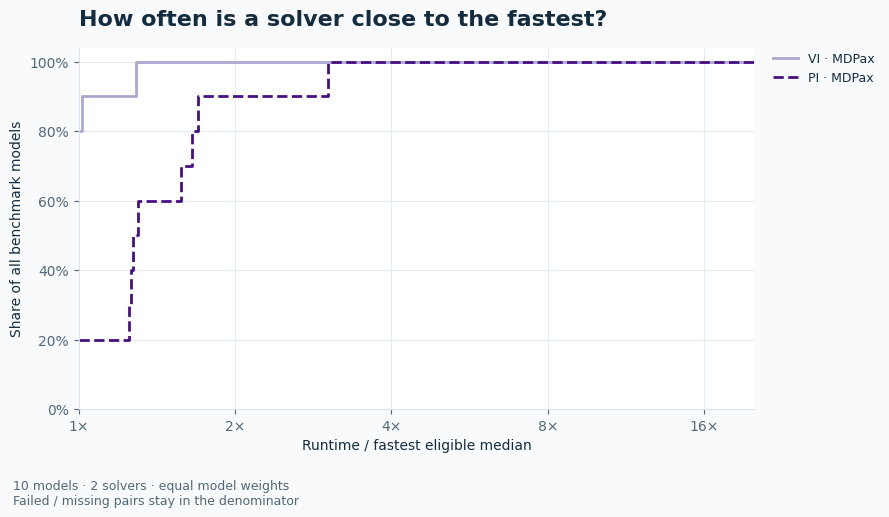

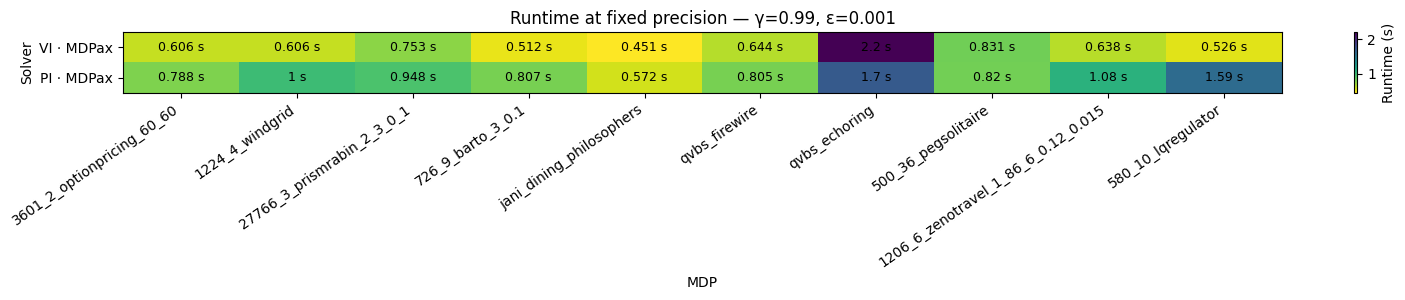

In [9]:
result_mdpax = run_backend("mdpax")

## QuantEcon

3601_2_optionpricing_60_60 / quantecon_mpi [1/5]: success (1.855 s)
3601_2_optionpricing_60_60 / quantecon_mpi [2/5]: success (0.831 s)
3601_2_optionpricing_60_60 / quantecon_mpi [3/5]: success (0.830 s)
3601_2_optionpricing_60_60 / quantecon_mpi [4/5]: success (0.829 s)
3601_2_optionpricing_60_60 / quantecon_mpi [5/5]: success (0.831 s)
3601_2_optionpricing_60_60 / quantecon_pi [1/5]: success (0.847 s)
3601_2_optionpricing_60_60 / quantecon_pi [2/5]: success (0.823 s)
3601_2_optionpricing_60_60 / quantecon_pi [3/5]: success (0.826 s)
3601_2_optionpricing_60_60 / quantecon_pi [4/5]: success (0.824 s)
3601_2_optionpricing_60_60 / quantecon_pi [5/5]: success (0.814 s)
3601_2_optionpricing_60_60 / quantecon_vi [1/5]: success (0.800 s)
3601_2_optionpricing_60_60 / quantecon_vi [2/5]: success (0.816 s)
3601_2_optionpricing_60_60 / quantecon_vi [3/5]: success (0.803 s)
3601_2_optionpricing_60_60 / quantecon_vi [4/5]: success (0.794 s)
3601_2_optionpricing_60_60 / quantecon_vi [5/5]: success 

,solver,models_solved,n_models,fastest_rate,within_2x,median_ratio
0,quantecon_mpi,10,10,0.4,1.0,1.005284
1,quantecon_pi,7,10,0.3,0.7,1.007857
2,quantecon_vi,10,10,0.3,1.0,1.007467


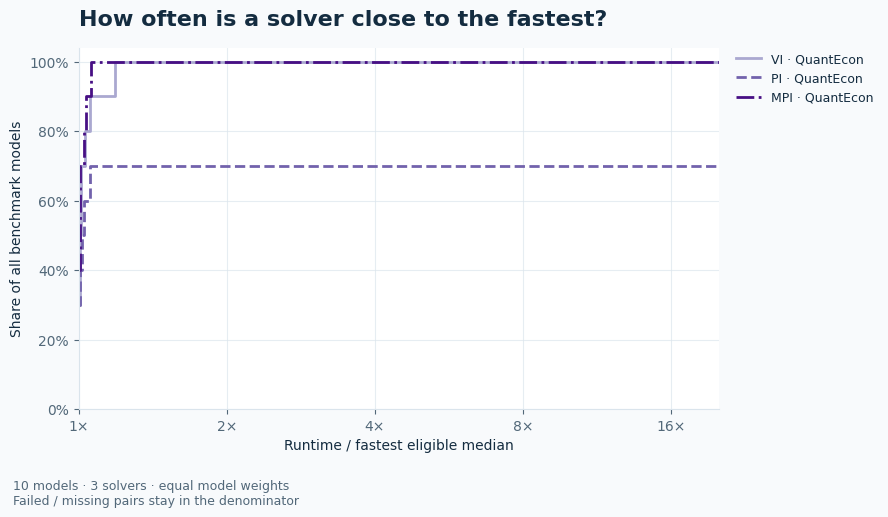

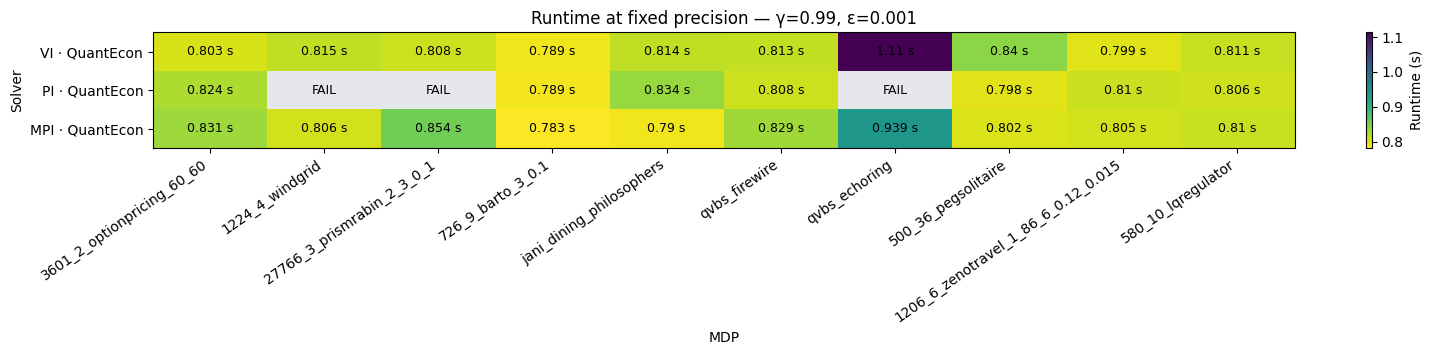

In [10]:
result_quantecon = run_backend("quantecon")

## Linear programming

3601_2_optionpricing_60_60 / pyomo_dual [1/5]: success (0.551 s)
3601_2_optionpricing_60_60 / pyomo_dual [2/5]: success (0.486 s)
3601_2_optionpricing_60_60 / pyomo_dual [3/5]: success (0.486 s)
3601_2_optionpricing_60_60 / pyomo_dual [4/5]: success (0.494 s)
3601_2_optionpricing_60_60 / pyomo_dual [5/5]: success (0.491 s)
3601_2_optionpricing_60_60 / pyomo_primal [1/5]: success (0.397 s)
3601_2_optionpricing_60_60 / pyomo_primal [2/5]: success (0.391 s)
3601_2_optionpricing_60_60 / pyomo_primal [3/5]: success (0.385 s)
3601_2_optionpricing_60_60 / pyomo_primal [4/5]: success (0.404 s)
3601_2_optionpricing_60_60 / pyomo_primal [5/5]: success (0.399 s)
3601_2_optionpricing_60_60 / quantecon_lp [1/5]: success (3.184 s)
3601_2_optionpricing_60_60 / quantecon_lp [2/5]: success (3.243 s)
3601_2_optionpricing_60_60 / quantecon_lp [3/5]: success (3.173 s)
3601_2_optionpricing_60_60 / quantecon_lp [4/5]: success (3.164 s)
3601_2_optionpricing_60_60 / quantecon_lp [5/5]: success (3.161 s)
3601_

,solver,models_solved,n_models,fastest_rate,within_2x,median_ratio
0,pyomo_dual,9,10,0.0,0.0,11.207206
1,pyomo_primal,8,10,0.0,0.0,14.633643
2,quantecon_lp,8,10,0.0,0.0,43.132838
3,scipy_dual,10,10,0.2,0.6,1.791495
4,scipy_primal,10,10,0.8,0.9,1.000000


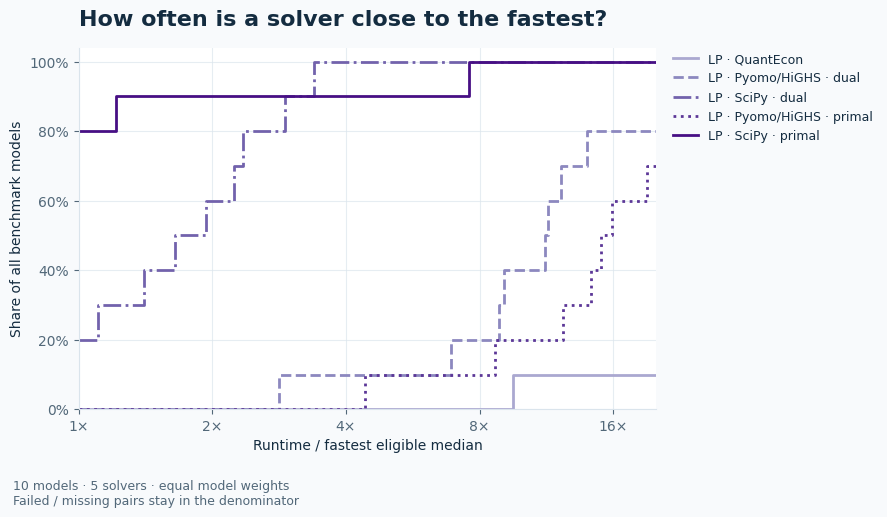

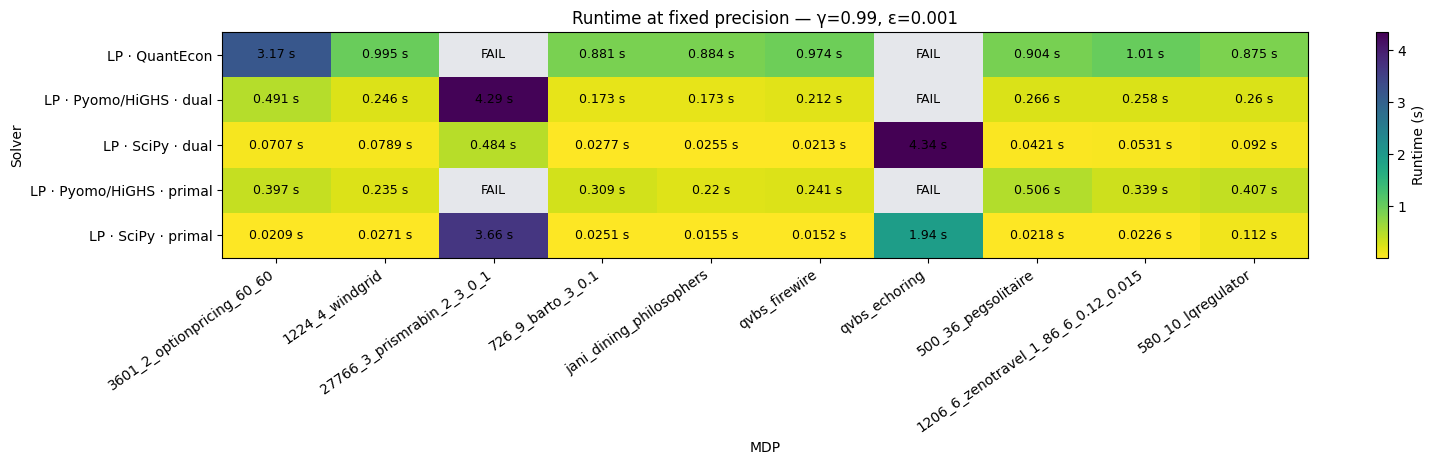

In [11]:
result_linear = run_backend("linear")

## Compare your chosen solvers

Fill in one solver ID per backend below, using the IDs shown in the profiles. Leave a value as `None` to omit that backend. No solver is chosen automatically. Run the final cell to measure your selected methods together on the shared sample.

In [12]:
CHOSEN_SOLVERS = {
    "marmote": None,
    "mdpsolver": None,
    "mdptoolbox": None,
    "madupite": None,
    "mdpax": None,
    "quantecon": None,
    "linear": None,
}

In [13]:
chosen = {
    backend: name for backend, name in CHOSEN_SOLVERS.items() if name is not None
}
if chosen:
    for backend, name in chosen.items():
        entry = solver_entries.get(name)
        if backend not in BACKENDS or entry is None or entry["backend"] != backend:
            raise ValueError(f"{name!r} is not a {CRITERION} solver for {backend!r}")
    bench.reset(models=False)
    for backend, name in chosen.items():
        bench.add_solver(name, **solver_options(backend))
    result_chosen = run_registered("chosen")
else:
    print("Fill in CHOSEN_SOLVERS, then rerun this cell to compare your choices.")

Fill in CHOSEN_SOLVERS, then rerun this cell to compare your choices.
